In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
df = pd.read_csv(r"C:\Users\konda\OneDrive\Downloads\movie_ratings_analysis_650_movies.csv")

In [13]:
df.head()

,Movie_ID,Title,Genre,Release_Year,Director,Runtime_Minutes,Rating,Votes,Revenue_Million,Language,Country,Budget_Million
0,M0642,Burning Future,Animation,2000,David Miller,80,7.3,72461,74.52,Hindi,India,21.22
1,M0225,City Empire,Animation,2000,Hans Weber,103,7.8,33423,201.72,English,Canada,70.55
2,M0447,City Horizon,Comedy,2000,David Miller,105,7.2,354697,75.77,English,USA,41.85
3,M0175,City War,Romance,2000,James Carter,95,6.1,165315,122.68,Hindi,India,22.01
4,M0560,Crimson Moon,Action,2000,Vikram Kapoor,149,6.9,21023,22.49,Hindi,India,6.90


In [14]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns)

Rows: 650
Columns: 12
Index(['Movie_ID', 'Title', 'Genre', 'Release_Year', 'Director',
       'Runtime_Minutes', 'Rating', 'Votes', 'Revenue_Million', 'Language',
       'Country', 'Budget_Million'],
      dtype='str')


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 650 entries, 0 to 649
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Movie_ID         650 non-null    str    
 1   Title            650 non-null    str    
 2   Genre            650 non-null    str    
 3   Release_Year     650 non-null    int64  
 4   Director         650 non-null    str    
 5   Runtime_Minutes  650 non-null    int64  
 6   Rating           650 non-null    float64
 7   Votes            650 non-null    int64  
 8   Revenue_Million  650 non-null    float64
 9   Language         650 non-null    str    
 10  Country          650 non-null    str    
 11  Budget_Million   650 non-null    float64
dtypes: float64(3), int64(3), str(6)
memory usage: 91.7 KB


In [16]:
df.isnull().sum()

Movie_ID           0
Title              0
Genre              0
Release_Year       0
Director           0
Runtime_Minutes    0
Rating             0
Votes              0
Revenue_Million    0
Language           0
Country            0
Budget_Million     0
dtype: int64

In [19]:
df.columns = df.columns.str.strip()

df["Genre"] = df["Genre"].astype(str).str.strip()
df["Title"] = df["Title"].astype(str).str.strip()
numeric_columns = [
    "Release_Year",
    "Runtime_Minutes",
    "Rating",
    "Votes",
    "Revenue_Million",
    "Budget_Million"
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Genre", "Release_Year", "Rating"])
print(df.shape)

(650, 12)


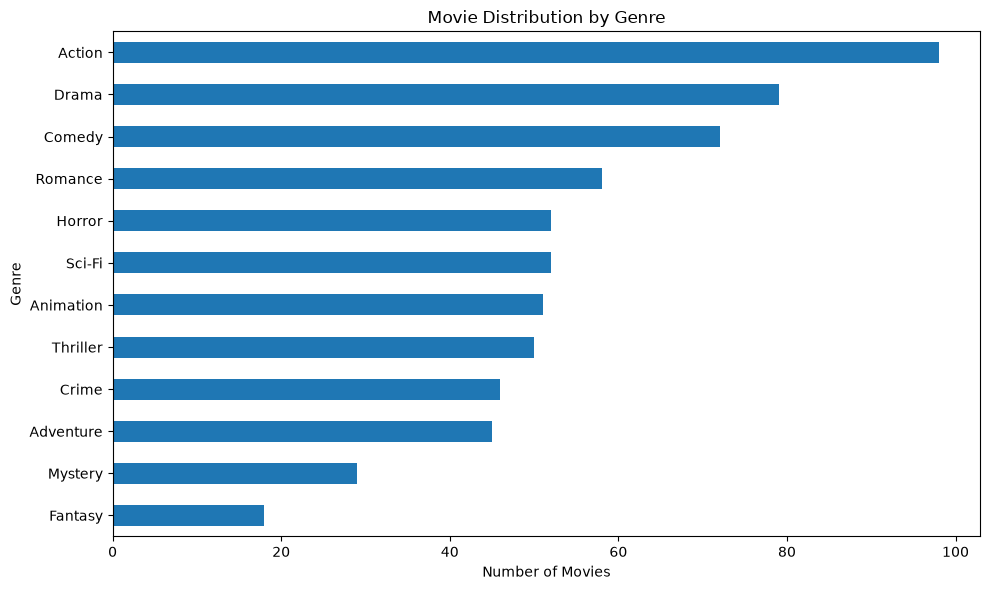

In [20]:
genre_counts = df["Genre"].value_counts().sort_values()

plt.figure(figsize=(10,6))
genre_counts.plot(kind="barh")

plt.title("Movie Distribution by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

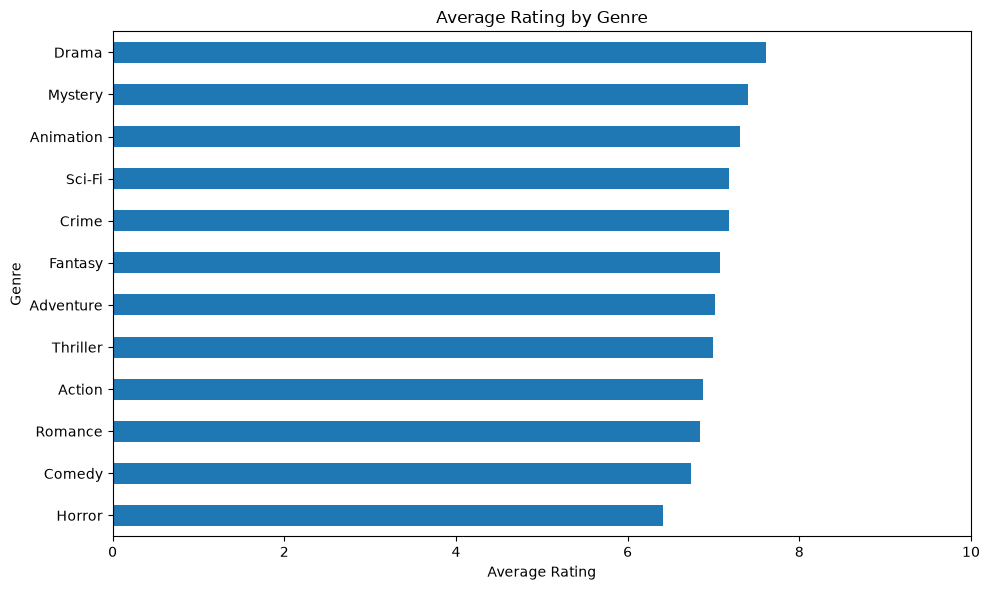

In [21]:
avg_rating = df.groupby("Genre")["Rating"].mean().sort_values()

plt.figure(figsize=(10,6))
avg_rating.plot(kind="barh")

plt.title("Average Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")
plt.xlim(0,10)
plt.tight_layout()
plt.show()

In [23]:
year_counts = df["Release_Year"].value_counts().sort_index()

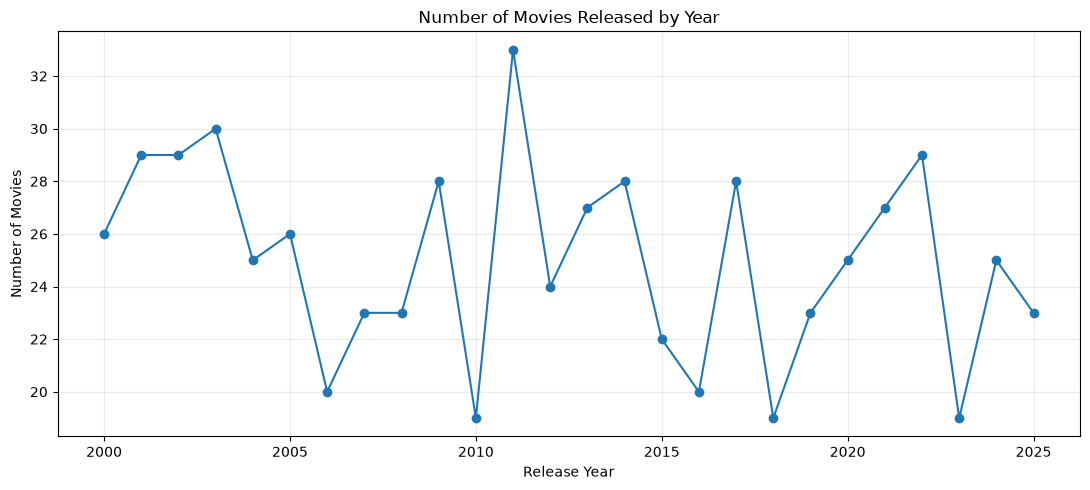

In [24]:
plt.figure(figsize=(11,5))
year_counts.plot(kind="line", marker="o")

plt.title("Number of Movies Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [25]:
most_popular_year = df["Release_Year"].value_counts().idxmax()
print("Most popular year:", most_popular_year)

Most popular year: 2011


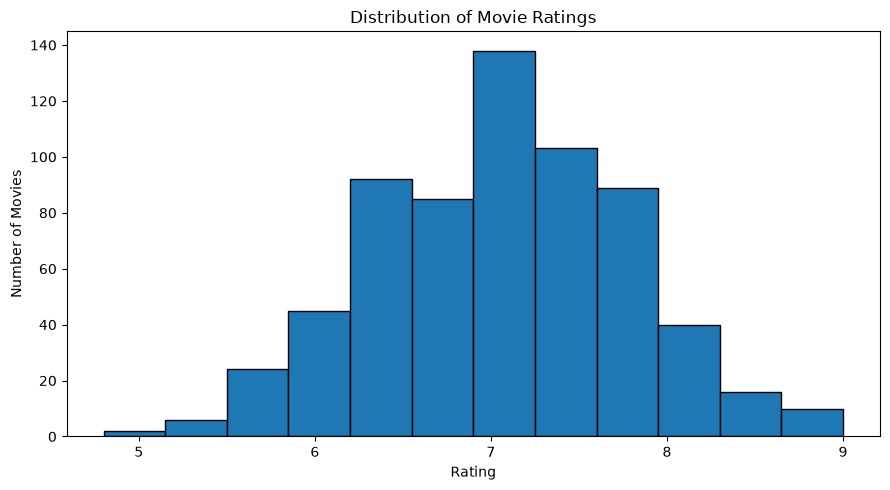

In [26]:
plt.figure(figsize=(9,5))

df["Rating"].plot(
kind="hist",
bins=12,
edgecolor="black"
)
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

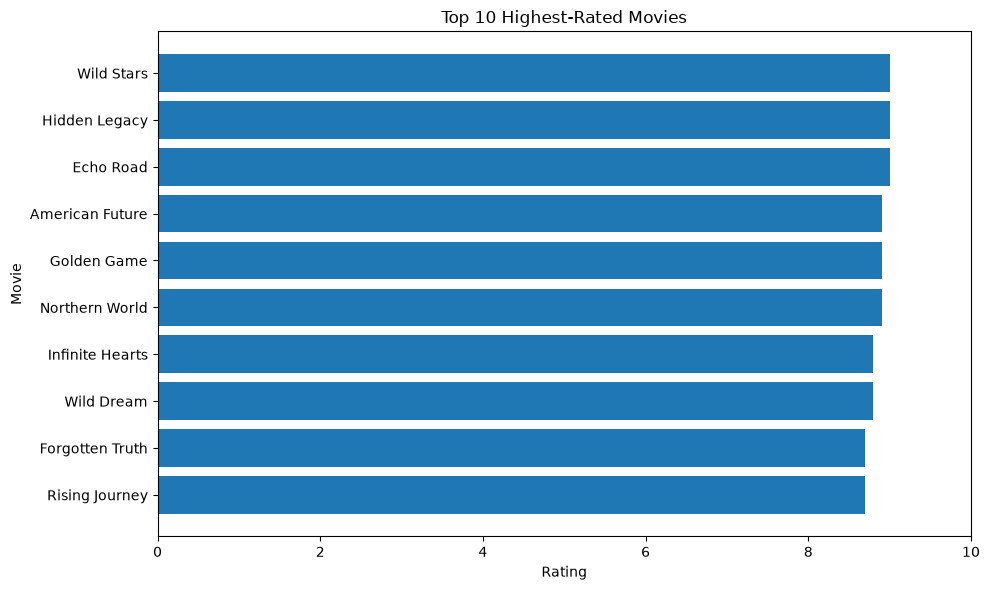

In [27]:
top10 = df.nlargest(10, "Rating").sort_values("Rating")

plt.figure(figsize=(10,6))
plt.barh(
top10["Title"],
top10["Rating"]
)
plt.title("Top 10 Highest-Rated Movies")
plt.xlabel("Rating")
plt.ylabel("Movie")
plt.xlim(0,10)
plt.tight_layout()
plt.show()

In [28]:
print(top10[[
"Title",
"Genre",
"Release_Year",
"Rating",
"Votes"
]])

               Title      Genre  Release_Year  Rating   Votes
157   Rising Journey  Animation          2005     8.7   57142
96   Forgotten Truth      Crime          2003     8.7  262938
410       Wild Dream     Sci-Fi          2015     8.8  394047
513  Infinite Hearts  Animation          2020     8.8   48126
103   Northern World    Mystery          2003     8.9  210847
614      Golden Game      Drama          2024     8.9  193970
55   American Future     Sci-Fi          2002     8.9   41670
238        Echo Road     Comedy          2009     9.0   97476
97     Hidden Legacy    Mystery          2003     9.0   43614
24        Wild Stars      Drama          2000     9.0   45487


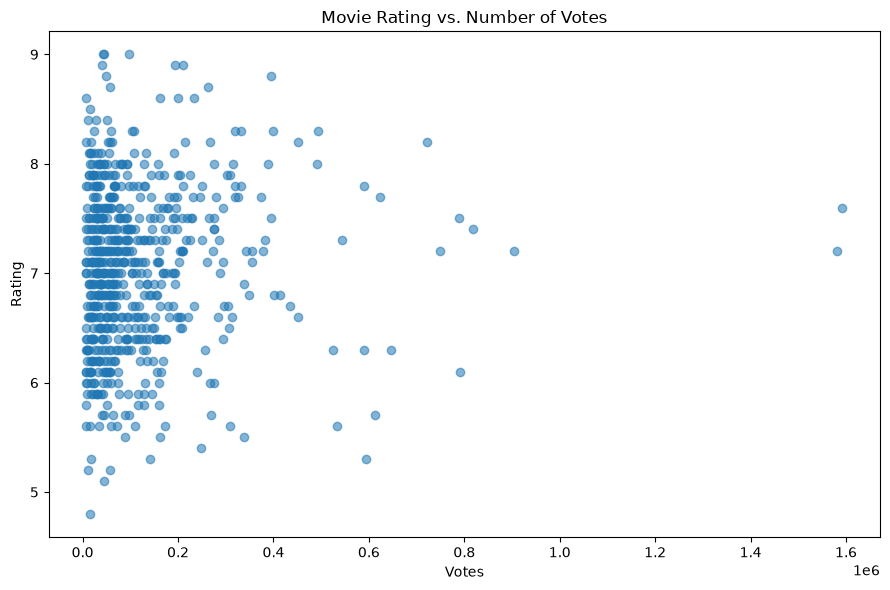

In [29]:
plt.figure(figsize=(9,6))

plt.scatter(
df["Votes"],
df["Rating"],
alpha=0.55
)
plt.title("Movie Rating vs. Number of Votes")
plt.xlabel("Votes")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

In [30]:
correlation = df[["Rating", "Votes"]].corr().iloc[0,1]
print("Correlation:", correlation)

Correlation: 0.072691207605979


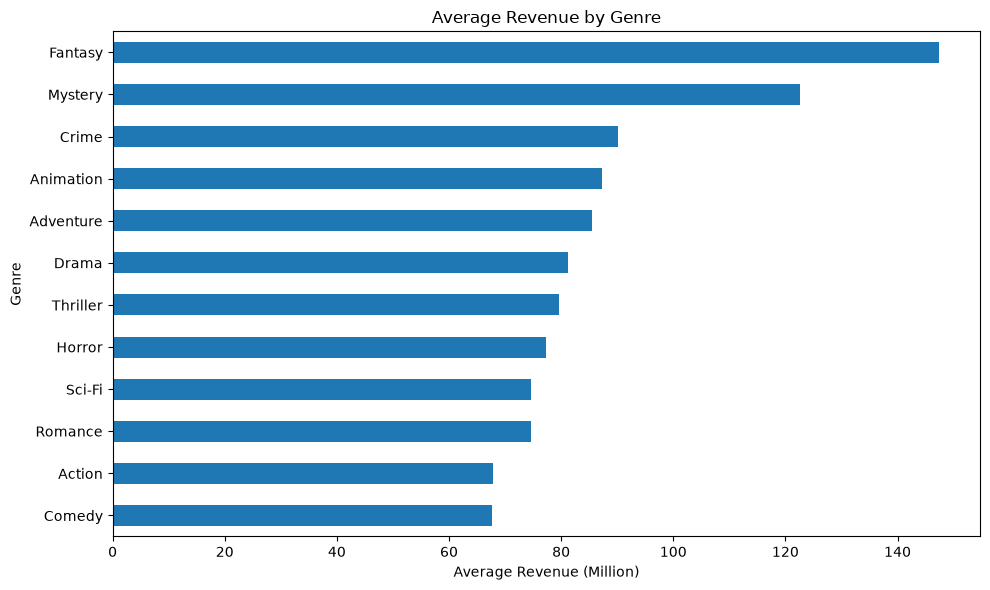

In [31]:
avg_revenue = df.groupby("Genre")["Revenue_Million"].mean().sort_values()

plt.figure(figsize=(10,6))
avg_revenue.plot(kind="barh")
plt.title("Average Revenue by Genre")
plt.xlabel("Average Revenue (Million)")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()